In [ ]:
import importlib
from src.dataprocessor import * 
import src.func_utils
from src.modeltrainer import * 
from src.func_utils import *
import src.dataprocessor
import src.modeltrainer
importlib.reload(src.modeltrainer)
importlib.reload(src.dataprocessor)
importlib.reload(src.func_utils)
from src.dataprocessor import *
from src.modeltrainer import * 
from src.func_utils import *

Xtrain_molecular: str = r"./data/molecular_train.csv"
Xtrain_clinical: str = r"./data/clinical_train.csv"
target_train: str = r"./data/target_train.csv"

data_train_mol: pd.DataFrame = pd.read_csv(Xtrain_molecular)
data_train_cli: pd.DataFrame = pd.read_csv(Xtrain_clinical)
target_df: pd.DataFrame = pd.read_csv(target_train)

# Convert 'OS_YEARS' to numeric, forcing errors to NaN 

target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

data = DataProcessor(data_train_mol, data_train_cli, target_df)

On visualise rapidement nos données pour se familiariser avec : 

In [72]:
data.show()
data.get_data_shapes()

Molecular Data :
        ID CHR        START          END                REF ALT    GENE  \
0  P100000  11  119149248.0  119149248.0                  G   A     CBL   
1  P100000   5  131822301.0  131822301.0                  G   T    IRF1   
2  P100000   3   77694060.0   77694060.0                  G   C   ROBO2   
3  P100000   4  106164917.0  106164917.0                  G   T    TET2   
4  P100000   2   25468147.0   25468163.0  ACGAAGAGGGGGTGTTC   A  DNMT3A   

  PROTEIN_CHANGE                EFFECT     VAF   DEPTH  
0        p.C419Y  non_synonymous_codon  0.0830  1308.0  
1        p.Y164*           stop_gained  0.0220   532.0  
2            p.?   splice_site_variant  0.4100   876.0  
3       p.R1262L  non_synonymous_codon  0.4300   826.0  
4   p.E505fs*141    frameshift_variant  0.0898   942.0  

Clinical Data :
        ID CENTER  BM_BLAST    WBC  ANC  MONOCYTES    HB    PLT  \
0  P132697    MSK      14.0    2.8  0.2        0.7   7.6  119.0   
1  P132698    MSK       1.0    7.4  2.4

'the molecular data shape: (10935, 11), clinical data shape: (3323, 9), target data shape: (3323, 3)'

On s'interesse à la fréquence de nos variable, ainsi que leurs valeurs manquantes


In [73]:
freq_mol = variable_frequency_table(data.molecular_data)
freq_mol

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3026,10935,0,100.00%
1,CHR,23,10821,114,98.96%
2,START,4645,10821,114,98.96%
3,END,4664,10821,114,98.96%
4,REF,406,10821,114,98.96%
5,ALT,332,10821,114,98.96%
6,GENE,124,10935,0,100.00%
7,PROTEIN_CHANGE,4686,10923,12,99.89%
8,EFFECT,16,10935,0,100.00%
9,VAF,2952,10846,89,99.19%


On voit que les variables START / END / REF /ALT / PROTEIN_Change ont une très grande variabilité, vis à vis du nombre d'observation qu'on détient, nous n'allons donc pas les conserver.

In [74]:
mol_col_to_remove = ["START","END","REF","ALT","PROTEIN_CHANGE"]
data.remove_columns(mol_col_to_remove, data_type="molecular")

On va faire pareil pour clinique

In [75]:
freq_clin = variable_frequency_table(data.clinical_data)
freq_clin

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3323,3323,0,100.00%
1,CENTER,23,3323,0,100.00%
2,BM_BLAST,139,3214,109,96.72%
3,WBC,699,3051,272,91.81%
4,ANC,1026,3130,193,94.19%
5,MONOCYTES,609,2722,601,81.91%
6,HB,239,3213,110,96.69%
7,PLT,586,3199,124,96.27%
8,CYTOGENETICS,1194,2936,387,88.35%


Dans le tableau de variable clinique, la seul qui puisse poser problème c'est celle CYTOGENETICS, cependant cette variable contient beaucoup trop d'information pour qu'on puisse juste s'en debarasser, de ce fait nous allons essayer de la transformer.

In [76]:
data.apply_cytogenetics_classification()
data.create_cytogenetics_dummies()

,ID,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTO_defavorable,CYTO_intermediaire,CYTO_normal
0,P132697,MSK,14.0,2.80,0.20,0.70,7.6,119.0,False,True,False
1,P132698,MSK,1.0,7.40,2.40,0.10,11.6,42.0,False,False,True
2,P116889,MSK,15.0,3.70,2.10,0.10,14.2,81.0,True,False,False
3,P132699,MSK,1.0,3.90,1.90,0.10,8.9,77.0,False,True,False
4,P132700,MSK,6.0,128.00,9.70,0.90,11.1,195.0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
3318,P121828,VU,1.0,3.70,2.53,0.53,8.9,499.0,False,False,True
3319,P121829,VU,0.0,4.20,2.40,0.22,10.6,49.0,False,True,False
3320,P121830,VU,0.0,1.80,0.55,0.29,9.4,86.0,True,False,False
3321,P121853,VU,5.0,1.37,0.37,0.11,11.4,102.0,False,True,False


Comme expliqué dans le rapport on crée une variable danger 

In [77]:
data.add_danger()
data.aggregate_genes()
data.temporary.head()

,ID,DANGER,GENE_ABL1,GENE_ARID1A,GENE_ARID2,GENE_ASXL1,GENE_ASXL2,GENE_ATRX,GENE_BAP1,GENE_BCL10,...,WBC,ANC,MONOCYTES,HB,PLT,CYTO_defavorable,CYTO_intermediaire,CYTO_normal,OS_YEARS,OS_STATUS
0,P100000,1323.4786,False,False,False,False,False,False,False,False,...,7.50,4.65,NaN,8.8,406.0,True,False,False,5.819178,False
1,P100001,271.2100,False,False,False,False,False,False,False,False,...,7.21,2.88,NaN,9.8,364.0,True,False,False,2.857534,False
2,P100002,351.8090,False,False,False,False,False,False,False,False,...,2.60,0.49,NaN,8.9,35.0,True,False,False,0.306849,True
3,P100004,607.9536,False,False,False,False,False,False,False,False,...,2.55,1.56,NaN,7.0,708.0,False,False,True,5.186301,False
4,P100006,490.1980,False,False,False,False,False,False,False,False,...,1.23,0.48,NaN,7.6,105.0,False,True,False,4.917808,False


In [78]:
resultats = clean_features_by_type(data.temporary,target_col="OS_YEARS")

CLASSIFICATION DES VARIABLES
Variables quantitatives (7):
  DANGER, BM_BLAST, WBC, ANC, MONOCYTES, HB, PLT

Variables qualitatives (169):
  ID, GENE_ABL1, GENE_ARID1A, GENE_ARID2, GENE_ASXL1, GENE_ASXL2, GENE_ATRX, GENE_BAP1, GENE_BCL10, GENE_BCOR...

CALCUL DES ASSOCIATIONS AVEC LA CIBLE

NETTOYAGE DES VARIABLES QUANTITATIVES
Initial: 7 variables
Conservées: 4 variables
Supprimées: 3 variables

Variables quantitatives sélectionnées (par corrélation):
  - PLT: |r| = 0.177
  - HB: |r| = 0.174
  - BM_BLAST: |r| = 0.156
  - DANGER: |r| = 0.130

NETTOYAGE DES VARIABLES QUALITATIVES
Initial: 169 variables
Conservées: 39 variables
Supprimées: 130 variables

Variables qualitatives sélectionnées (par p-value Chi²):
  - OS_STATUS: p = 0.0000
  - GENE_TP53: p = 0.0000
  - CENTER: p = 0.0000
  - CHR_17: p = 0.0000
  - CYTO_defavorable: p = 0.0000
  - CHR_21: p = 0.0000
  - GENE_RUNX1: p = 0.0000
  - GENE_SF3B1: p = 0.0000
  - CYTO_normal: p = 0.0000
  - GENE_ASXL1: p = 0.0000
  - CHR_1: p = 0.000

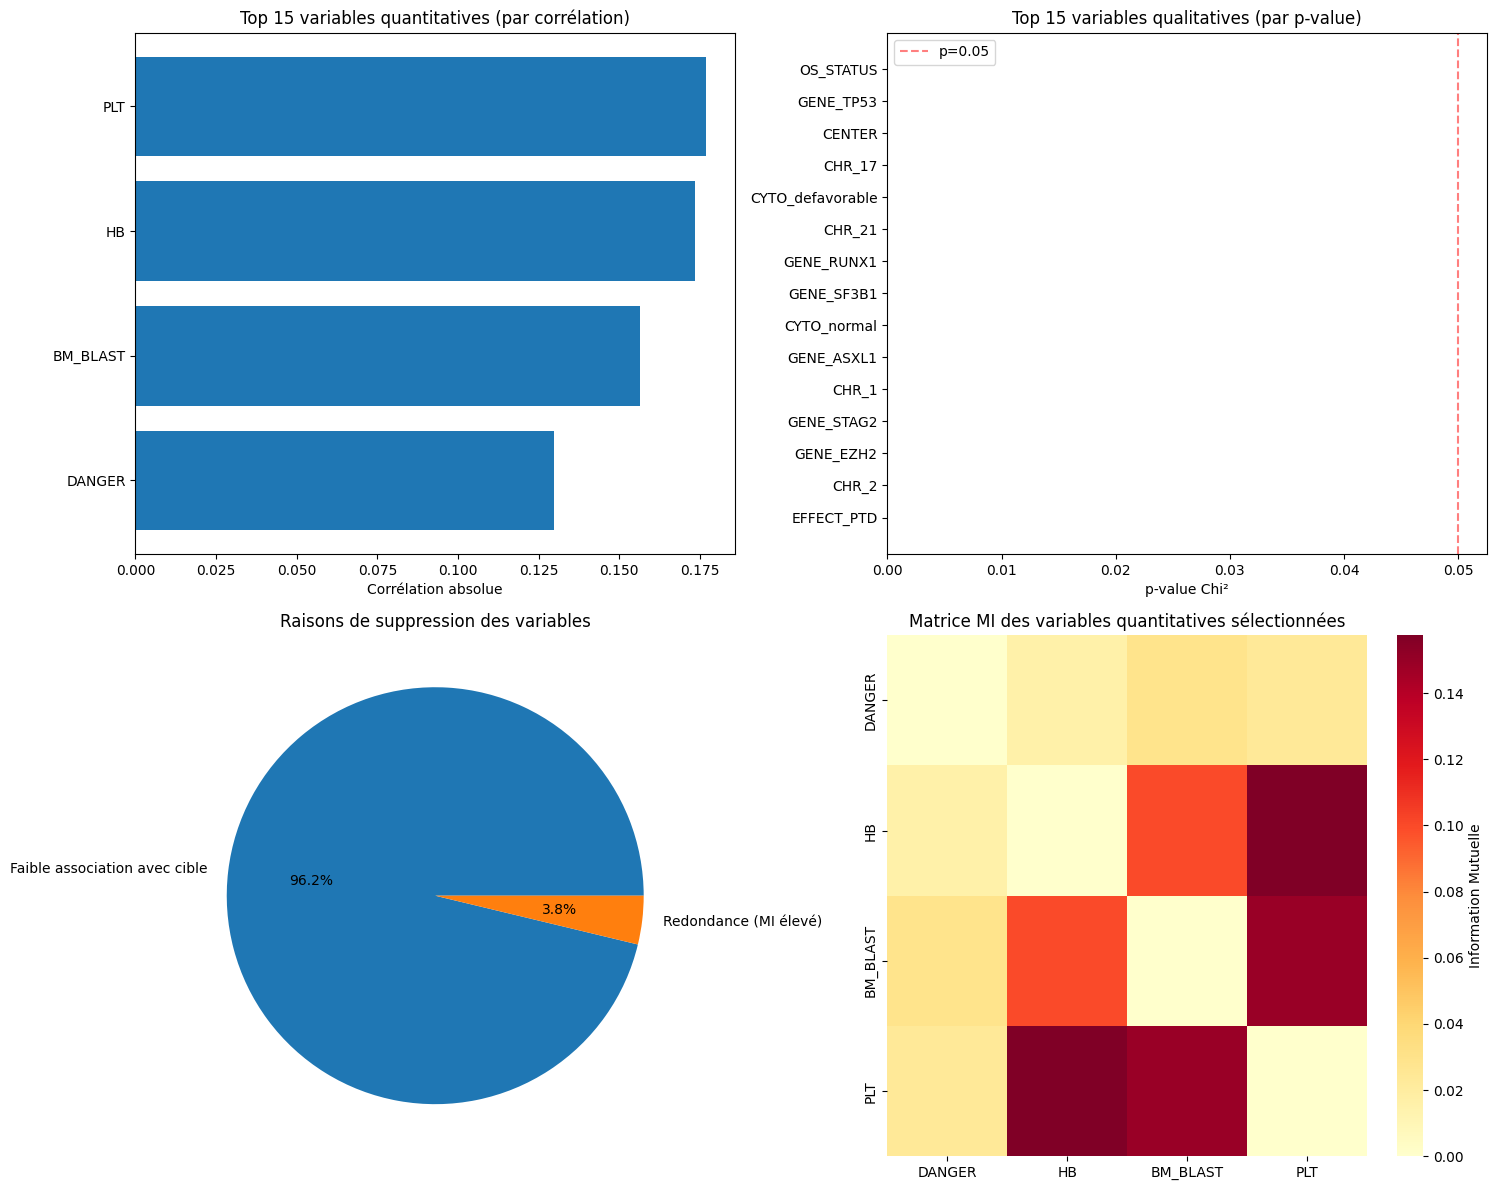

In [79]:
visualize_cleaning_results(resultats)

In [80]:
cols_for_training = resultats[1] + resultats[2]
cols_for_training.remove("OS_STATUS")
cols_for_training

['DANGER',
 'HB',
 'BM_BLAST',
 'PLT',
 'GENE_ASXL1',
 'CHR_1',
 'CHR_19',
 'CHR_21',
 'GENE_CDKN2A',
 'GENE_FLT3',
 'GENE_PTPN11',
 'GENE_CUX1',
 'GENE_GATA2',
 'GENE_CEBPA',
 'CHR_4',
 'GENE_ETV6',
 'CHR_X',
 'CHR_17',
 'GENE_NRAS',
 'CYTO_defavorable',
 'GENE_U2AF2',
 'GENE_RAD21',
 'GENE_STAG2',
 'CHR_13',
 'EFFECT_PTD',
 'CHR_2',
 'EFFECT_initiator_codon_change',
 'CYTO_normal',
 'GENE_SF3B1',
 'GENE_EZH2',
 'GENE_CBL',
 'GENE_NPM1',
 'GENE_RUNX1',
 'CHR_11',
 'GENE_SRSF2',
 'GENE_TP53',
 'GENE_BCOR',
 'EFFECT_frameshift_variant',
 'GENE_JAK2',
 'GENE_MLL',
 'CENTER',
 'GENE_U2AF1']

In [81]:
data.temporary[cols_for_training].isna().sum()

DANGER                             0
HB                               100
BM_BLAST                         100
PLT                              114
GENE_ASXL1                         0
CHR_1                              0
CHR_19                             0
CHR_21                             0
GENE_CDKN2A                        0
GENE_FLT3                          0
GENE_PTPN11                        0
GENE_CUX1                          0
GENE_GATA2                         0
GENE_CEBPA                         0
CHR_4                              0
GENE_ETV6                          0
CHR_X                              0
CHR_17                             0
GENE_NRAS                          0
CYTO_defavorable                   0
GENE_U2AF2                         0
GENE_RAD21                         0
GENE_STAG2                         0
CHR_13                             0
EFFECT_PTD                         0
CHR_2                              0
EFFECT_initiator_codon_change      0
C

Nous allons traiter les données manquantes par la suite

In [82]:
data.save_data()

,ID,DANGER,GENE_ABL1,GENE_ARID1A,GENE_ARID2,GENE_ASXL1,GENE_ASXL2,GENE_ATRX,GENE_BAP1,GENE_BCL10,...,WBC,ANC,MONOCYTES,HB,PLT,CYTO_defavorable,CYTO_intermediaire,CYTO_normal,OS_YEARS,OS_STATUS
0,P100000,1323.4786,False,False,False,False,False,False,False,False,...,7.50,4.65,NaN,8.8,406.0,True,False,False,5.819178,False
1,P100001,271.2100,False,False,False,False,False,False,False,False,...,7.21,2.88,NaN,9.8,364.0,True,False,False,2.857534,False
2,P100002,351.8090,False,False,False,False,False,False,False,False,...,2.60,0.49,NaN,8.9,35.0,True,False,False,0.306849,True
3,P100004,607.9536,False,False,False,False,False,False,False,False,...,2.55,1.56,NaN,7.0,708.0,False,False,True,5.186301,False
4,P100006,490.1980,False,False,False,False,False,False,False,False,...,1.23,0.48,NaN,7.6,105.0,False,True,False,4.917808,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3021,P132725,4365.4240,False,False,False,True,False,False,False,False,...,2.00,0.60,0.2,11.5,61.0,False,False,True,4.290411,False
3022,P132726,347.0100,False,False,False,False,False,False,False,False,...,1.90,0.50,0.0,11.2,383.0,False,False,True,2.279452,False
3023,P132727,816.5240,False,False,False,True,False,False,False,False,...,2.30,1.00,0.4,11.3,44.0,False,False,True,0.578082,False
3024,P132728,2989.9348,False,False,False,False,True,False,False,False,...,44.90,40.10,2.3,8.2,14.0,False,True,False,1.284932,True
